# Search policy ablation — greedy vs. archive

Run 2026-08-10. GRU seed, 120 evaluations per arm, **selection policy is the only variable**.

Reads `results.tsv` and `archive/*.py` from each worktree. Figures go to
`runs/search_policy_ablation__aug10/figs/`.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

WS   = Path.home() / "srip/windevolve_sdwpf/arms/karpathy/ws"
FIGS = Path.home() / "srip/windevolve_sdwpf/runs/search_policy_ablation__aug10/figs"
FIGS.mkdir(parents=True, exist_ok=True)

INVALID = 999.0                      # sentinel: invalid / crash / retrain rows carry no score
SEED    = 44.53736578814683          # both arms start here

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.transparent": True,
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
})

def load(arm):
    df = pd.read_csv(WS / arm / "results.tsv", sep="\t", dtype={"id": str, "parent_id": str})
    df["n"]     = np.arange(1, len(df) + 1)                    # evaluation index
    df["valid"] = df.competition_score < INVALID
    df["score"] = df.competition_score.where(df.valid)          # NaN where no score
    df["best"]  = df.score.cummin().ffill()
    df["arm"]   = arm
    return df

greedy, archive = load("greedy-gru"), load("archive-gru")
for df, lab in [(greedy, "greedy"), (archive, "archive")]:
    print(f"{lab:8s} {len(df):3d} rows | {df.valid.sum():3d} scored | best {df.best.iloc[-1]:.6f} MW")

greedy   120 rows | 116 scored | best 43.727938 MW
archive  120 rows | 113 scored | best 42.862917 MW


## 1. Budget composition

How each arm spent its 120 evaluations. The status vocabularies differ by design —
greedy logs `keep`/`discard` because it makes a keep decision; archive logs `scored`
because it never discards anything.

The row to look at is `retrain`.

In [2]:
comp = pd.concat([
    greedy.status.value_counts().rename("greedy"),
    archive.status.value_counts().rename("archive"),
], axis=1).fillna(0).astype(int)
print(comp.to_string())

         greedy  archive
status                  
discard      88        0
keep         26        0
invalid       4        0
scored        2      113
retrain       0        7


### Why did greedy never retrain?

Retraining costs about an hour of wall-clock and is only worth it if you intend to keep
the network. Both arms could retrain up to 15 times; greedy chose zero. Its own notes
say why.

In [3]:
import textwrap

fm = (WS / "greedy-gru" / "FAILURE_MODES.md").read_text()
for para in fm.split("\n\n"):
    if "neural" in para.lower() or "gru" in para.lower():
        print(textwrap.fill(para.strip(), 96), "\n")

**009 and the shape of this problem.** Dropping the 1-3d block recovered 1.2 MW (47.263 ->
46.027) but the model still lost to the SINGLE-deviation version at 44.658. Four experiments now
say the same thing: 002/005 (one feature) 46.790/44.658, 006 (11 features) 46.381, 007 (7)
46.607, 008 (5) 47.263, 009 (4) 46.027. Every added degree of freedom cost score, and the seed
GRU -- which is a per-turbine CONSTANT -- still leads at 44.537. The conclusion is not that
these models are mis-fitted; it is that the forecastable signal at this horizon is tiny
(autocorrelation 0.20 at 24h, 0.02 at 48h) and the metric is decided almost entirely by where
the per-turbine LEVEL sits. Spend the remaining budget on the level estimator, not on richer
dynamics. Note also that a pure per-turbine constant cannot be submitted even to test this: 134
distinct values over 38592 predictions is a 0.003 distinct ratio and the grader's
min_distinct_ratio is 0.1, so some horizon variation is mandatory. 

**010 - neve

In [ ]:
# what greedy worked on in the evaluations after it wrote off the neural direction
print(greedy[["id", "parent_id", "score", "status", "description"]]
      .iloc[38:46].to_string(index=False))

## 2. Best-so-far trajectory

The headline. Solid lines are best-so-far; faint dots are individual attempts.

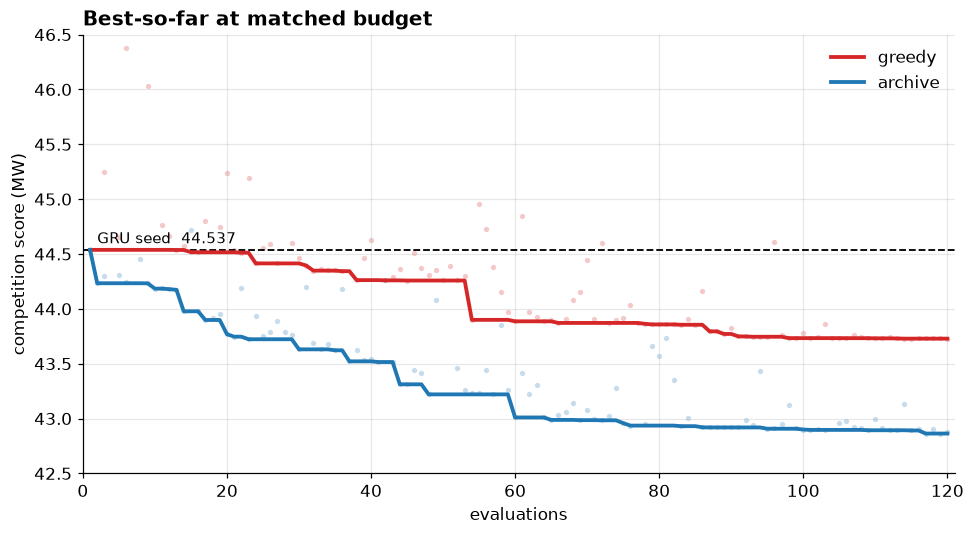

attempts clipped above the y-limit — greedy 5, archive 0


In [4]:
fig, ax = plt.subplots(figsize=(9, 5))

for df, col, lab in [(greedy, "tab:red", "greedy"), (archive, "tab:blue", "archive")]:
    v = df[df.valid]
    ax.scatter(v.n, v.score, s=12, color=col, alpha=0.25, linewidths=0)
    ax.plot(df.n, df.best, color=col, lw=2.5, label=lab, zorder=3)

ax.axhline(SEED, color="black", lw=1.2, ls="--", zorder=2)
ax.annotate(f"GRU seed  {SEED:.3f}", xy=(2, SEED + 0.06), fontsize=10)

ax.set_xlabel("evaluations")
ax.set_ylabel("competition score (MW)")
ax.set_title("Best-so-far at matched budget", loc="left", fontsize=13, weight="bold")
ax.set_xlim(0, 121)
ax.set_ylim(42.5, 46.5)
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(FIGS / "trajectory.png")
plt.show()

print("attempts clipped above the y-limit — greedy {}, archive {}".format(
    (greedy.score > 46.5).sum(), (archive.score > 46.5).sum()))

In [5]:
ck = pd.DataFrame({
    "greedy":  [greedy.best.iloc[k - 1]  for k in (20, 40, 60, 80, 100, 120)],
    "archive": [archive.best.iloc[k - 1] for k in (20, 40, 60, 80, 100, 120)],
}, index=[20, 40, 60, 80, 100, 120]).round(3)
ck["gap"] = (ck.greedy - ck.archive).round(3)
ck.index.name = "evals"
print(ck.to_string())

print("\nimprovement over the final 20 evaluations")
print(f"  greedy  {greedy.best.iloc[99]  - greedy.best.iloc[119]:.3f} MW")
print(f"  archive {archive.best.iloc[99] - archive.best.iloc[119]:.3f} MW")

       greedy  archive    gap
evals                        
20     44.515   43.769  0.746
40     44.262   43.521  0.741
60     43.886   43.009  0.877
80     43.858   42.935  0.923
100    43.733   42.900  0.833
120    43.728   42.863  0.865

improvement over the final 20 evaluations
  greedy  0.005 MW
  archive 0.037 MW


## 3. Valley crossing

The structural result, and the part that does **not** depend on having only one run per arm.

The logic, in three steps:

1. Under greedy, a program that scores worse than its own parent is deleted by
   `git reset --hard`. It cannot be edited again.
2. So for each program P in the archive arm, ask: *was P itself a regression on its own
   parent?* If yes, greedy would no longer have P.
3. Then ask whether any **child of P** went on to improve. If so, that is a lineage
   greedy structurally could not have followed — not because it was unlucky, but
   because the starting point no longer existed.

`gain` is parent score minus child score: how much the child improved on the program it
was edited from.

In [6]:
score_of  = archive.set_index("id").score.to_dict()
parent_of = archive.set_index("id").parent_id.to_dict()

def was_regression(pid):
    """True if program pid scored worse than the program IT was edited from."""
    gp = parent_of.get(pid)
    if gp is None or gp not in score_of or pid not in score_of:
        return False
    return score_of[pid] > score_of[gp]

lin = archive[archive.valid].copy()
lin["parent_score"] = lin.parent_id.map(score_of)
lin = lin.dropna(subset=["parent_score"])
lin["gain"] = lin.parent_score - lin.score
lin["parent_was_regression"] = lin.parent_id.map(was_regression)

revived = lin[lin.parent_was_regression & (lin.gain > 0)].sort_values("gain", ascending=False)
print(f"{len(revived)} children improved on a parent greedy would have deleted\n")
print(revived[["id", "score", "parent_id", "parent_score", "gain"]]
      .head(10).round(3).to_string(index=False))

beats = revived[revived.score < greedy.best.iloc[-1]]
print(f"\nof those, {len(beats)} ended below greedy's final score "
      f"({greedy.best.iloc[-1]:.3f} MW)")

18 children improved on a parent greedy would have deleted

 id  score parent_id  parent_score  gain
083 42.930       003        44.297 1.367
116 42.907       042        44.259 1.352
048 43.220       008        44.450 1.230
041 43.515       015        44.721 1.206
101 42.896       027        43.890 0.994
059 43.261       024        43.937 0.676
039 43.530       019        43.949 0.418
081 43.738       049        44.085 0.347
038 43.622       024        43.937 0.315
060 43.009       057        43.220 0.211

of those, 15 ended below greedy's final score (43.728 MW)


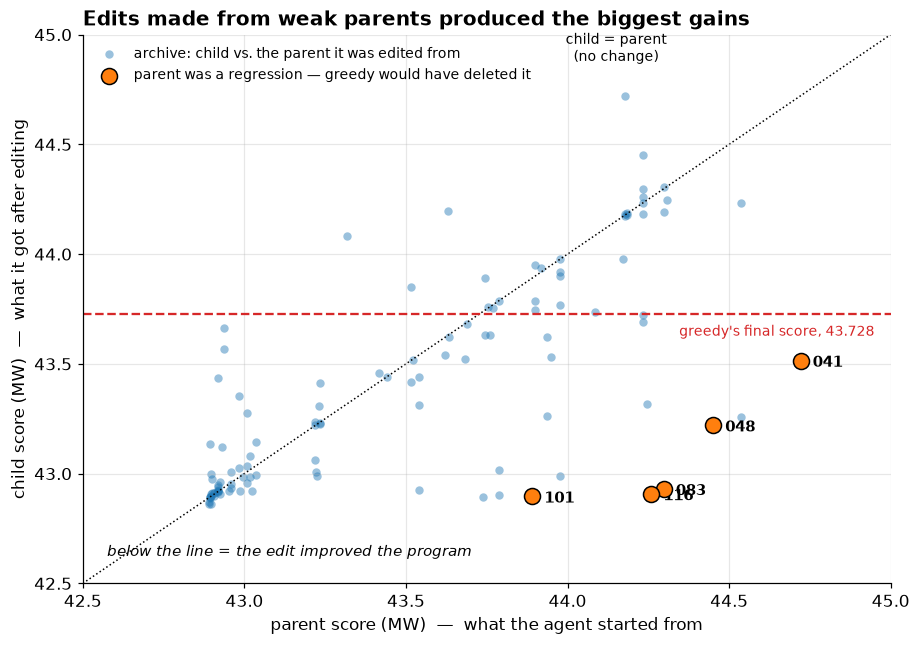

In [7]:
# How to read this plot:
#   x = score of the program the agent was handed
#   y = score it got after editing it
#   dotted diagonal = no change. BELOW the line = the edit improved things,
#                     because lower score is better.
#   orange = the parent was itself a regression, so greedy would have deleted it
#            and never reached the child at all.
fig, ax = plt.subplots(figsize=(8.5, 6))

ax.scatter(lin.parent_score, lin.score, s=30, color="tab:blue", alpha=0.45,
           linewidths=0, label="archive: child vs. the parent it was edited from")
r = revived.head(5)
ax.scatter(r.parent_score, r.score, s=110, color="tab:orange", edgecolor="black",
           linewidths=1.0, zorder=4,
           label="parent was a regression — greedy would have deleted it")
for _, row in r.iterrows():
    ax.annotate(row.id, (row.parent_score, row.score), xytext=(8, -4),
                textcoords="offset points", fontsize=10, weight="bold")

lo, hi = 42.5, 45.0
ax.plot([lo, hi], [lo, hi], color="black", lw=1, ls=":", zorder=1)
ax.annotate("child = parent\n(no change)", xy=(44.55, 44.55), xytext=(44.15, 44.88),
            fontsize=9, ha="center")
ax.annotate("below the line = the edit improved the program",
            xy=(0.03, 0.05), xycoords="axes fraction", fontsize=10, style="italic")

ax.axhline(greedy.best.iloc[-1], color="tab:red", lw=1.5, ls="--", zorder=2)
ax.annotate(f"greedy's final score, {greedy.best.iloc[-1]:.3f}",
            xy=(hi - 0.05, greedy.best.iloc[-1] - 0.1), fontsize=9,
            color="tab:red", ha="right")

ax.set_xlabel("parent score (MW)  —  what the agent started from")
ax.set_ylabel("child score (MW)  —  what it got after editing")
ax.set_title("Edits made from weak parents produced the biggest gains",
             loc="left", fontsize=13, weight="bold")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGS / "valley_crossing.png")
plt.show()

## 4. The single largest improvement in each arm

Which one edit gained the most, what it started from, what changed, and what the agent
said about it. This is the qualitative counterpart to the trajectory: *what kind of move*
each policy made possible.

In [8]:
def gains(df):
    """Score improvement of every child over the parent it was edited from."""
    s = df.set_index("id").score.to_dict()
    g = df[df.valid].copy()
    g["parent_score"] = g.parent_id.map(s)
    g = g.dropna(subset=["parent_score"])
    g["gain"] = g.parent_score - g.score
    return g.sort_values("gain", ascending=False)

for df, lab in [(greedy, "greedy"), (archive, "archive")]:
    print(f"=== {lab}: three largest single-edit gains")
    print(gains(df).head(3)[["id", "parent_id", "parent_score", "score", "gain", "description"]]
          .round(3).to_string(index=False), "\n")

=== greedy: three largest single-edit gains
 id parent_id  parent_score  score  gain                                                              description
054       042        44.259 43.899 0.360          level window 10 days instead of 14 - large gain on RMSE and MAE
024       022        44.511 44.414 0.097         30min persistence window - fresher state helps both RMSE and MAE
038       036        44.343 44.262 0.082 farm-wide 30min deviation as regime signal - first added feature to help 

=== archive: three largest single-edit gains
 id parent_id  parent_score  score  gain                                                                              description
083       003        44.297 42.930 1.367 scale 0.95 on hidden=128 weights - new best - bigger model needs less blanket correction
116       042        44.259 42.907 1.352                                       persistence weight 0.60 - brackets 0.70 as optimal
053       001        44.537 43.256 1.281         scale 0.95 on 

In [9]:
import difflib

def show_diff(arm, parent, child, context=2, max_lines=80):
    a = (WS / arm / "archive" / f"{parent}.py").read_text().splitlines()
    b = (WS / arm / "archive" / f"{child}.py").read_text().splitlines()
    print(f"--- {arm}: {parent}.py ({len(a)} lines)  ->  {child}.py ({len(b)} lines)")
    d = list(difflib.unified_diff(a, b, lineterm="", n=context))
    for line in d[:max_lines]:
        print(line)
    if len(d) > max_lines:
        print(f"... {len(d) - max_lines} more diff lines")

for df, arm in [(greedy, "greedy-gru"), (archive, "archive-gru")]:
    top = gains(df).iloc[0]
    show_diff(arm, top.parent_id, top.id)
    print("\n" + "=" * 96 + "\n")

--- greedy-gru: 042.py (363 lines)  ->  054.py (363 lines)
--- 
+++ 
@@ -61,5 +61,5 @@
 CAPACITY = 134       # turbines
 DAY_LEN = 144        # 10-minute observations per day
-CLIM_LEN = 14 * DAY_LEN   # trailing window for the climatology anchor (2016)
+CLIM_LEN = 10 * DAY_LEN   # trailing window for the climatology anchor (2016)
 RECENT_LEN = 3           # trailing window for the persistence anchor (1h)
 


--- archive-gru: 003.py (1049 lines)  ->  083.py (1130 lines)
--- 
+++ 
@@ -55,5 +55,5 @@
 
 from test_data import TestData               # official per-turbine window loader
-from paths import VAL_TRAIN_FILE
+from paths import VAL_TRAIN_FILE, LOCATION_FILE
 
 DAY_LEN = 144        # 10-minute observations per day
@@ -74,5 +74,9 @@
 
 # Folder holding model_0.pt ... model_133.pt (written by training, read by forecast).
-CHECKPOINTS = os.environ.get("SDWPF_GRU_CHECKPOINTS", os.path.join(_HERE, "checkpoints"))
+# Retrain 050 weights: 0.5*MSE + 0.5*L1 loss, GRU hidden size 128 (the se

### Case study: 003 → 083 in the archive arm

Program 003 scored 44.297 against its parent 002 at 44.233 — a regression, so greedy
would have deleted it. Eighty evaluations later the sampler handed it back, and the edit
made from it scored 42.930, beating the greedy arm's entire final result.

In [10]:
print(archive[archive.id.isin(["002", "003", "083"])]
      [["id", "parent_id", "score", "status", "description"]].to_string(index=False), "\n")

show_diff("archive-gru", "003", "083", context=1, max_lines=60)

 id parent_id     score status                                                                              description
002       001 44.232971 scored                                    scale predictions by 0.90 plus clip negatives to zero
003       002 44.297166 scored                                            scale 0.80 - overshoots, optimum is near 0.88
083       003 42.930125 scored scale 0.95 on hidden=128 weights - new best - bigger model needs less blanket correction 

--- archive-gru: 003.py (1049 lines)  ->  083.py (1130 lines)
--- 
+++ 
@@ -56,3 +56,3 @@
 from test_data import TestData               # official per-turbine window loader
-from paths import VAL_TRAIN_FILE
+from paths import VAL_TRAIN_FILE, LOCATION_FILE
 
@@ -75,3 +75,7 @@
 # Folder holding model_0.pt ... model_133.pt (written by training, read by forecast).
-CHECKPOINTS = os.environ.get("SDWPF_GRU_CHECKPOINTS", os.path.join(_HERE, "checkpoints"))
+# Retrain 050 weights: 0.5*MSE + 0.5*L1 loss, GRU hidden size 1

In [11]:
# The agent's own notes on the programs involved in the big moves.
import re

def notes_for(arm, ids):
    fm = (WS / arm / "FAILURE_MODES.md").read_text()
    for para in fm.split("\n\n"):
        if any(re.search(rf"\b0*{int(i)}\b", para) for i in ids):
            print(textwrap.fill(para.strip(), 96), "\n")

print("### archive-gru notes on 003 / 083 / 116\n")
notes_for("archive-gru", ["003", "083", "116"])

### archive-gru notes on 003 / 083 / 116

**Test-time ensembling over lagged origins (008).** Re-issuing the forecast from origins T, T-3,
T-6, T-12 and averaging the members covering each horizon step scored 44.450 against 44.233 for
the single origin -- a 0.22 MW loss. The mistake was treating the members as independent draws.
They are not: a run issued at T-l is forecasting the same absolute time from l steps further
back, so it is *strictly staler*, not an equally-good opinion. Equal-weight averaging a good
forecast with three worse ones moves the answer toward the worse ones. Ensembling only reduces
variance when members have comparable skill and uncorrelated errors; neither holds across
forecast origins of the same deterministic model. Any future ensemble has to come from genuinely
different models (different seeds, architectures, or losses), not different input offsets. 

**Diurnal shape estimated from the infile (019).** The GRU is time-blind (start_col=3 drops
Tmstamp) and its

## 5. Did the network survive?

Each arm's champion, and whether it still contains the seeded GRU.

In [12]:
champs = {}
for df, arm in [(greedy, "greedy-gru"), (archive, "archive-gru")]:
    c   = df.loc[df.score.idxmin()]
    src = (WS / arm / "archive" / f"{c.id}.py").read_text()
    ck_dir = re.search(r"ckpt_\w+", src)
    champs[arm] = c.id
    print(f"{arm:12s} champion {c.id}  {c.score:.6f} MW")
    print(f"   torch / GRU / nn.Module refs : {len(re.findall(r'torch|GRU|nn[.]Module', src))}")
    print(f"   checkpoints used             : {ck_dir.group(0) if ck_dir else 'seed ./checkpoints'}")
    print(f"   lines                        : {len(src.splitlines())}")
    print(f"   {c.description}\n")

greedy-gru   champion 115  43.727938 MW
   torch / GRU / nn.Module refs : 5
   checkpoints used             : seed ./checkpoints
   lines                        : 482
   shade bound 0.2-2.2 - now a safety guard not a constraint

archive-gru  champion 117  42.862917 MW
   torch / GRU / nn.Module refs : 67
   checkpoints used             : ckpt_050
   lines                        : 1185
   zero pull floor on final architecture - new best - gain 0.028



## 6. Final test-set score

Everything above is **validation**. `evaluation/competition_score.py` is the
leaderboard-comparable scorer — it runs the official Baidu grader over the locked
`final_phase_test` set (142 windows). Run **once per completed arm**, never as a search
signal.

Two things to keep in mind:

- Validation-to-test rank transfer on this benchmark is poor (Spearman ρ ≈ −0.20 across
  five baselines), so the test gap need not track the validation gap.
- The archive champion loads weights from `.cache/ckpt_050/`, trained on `VAL_TRAIN_FILE`
  (days 1–197). Scoring on test with val-split weights is legitimate — no leakage — but
  it under-uses the available history, so this is a floor rather than the arm's best
  possible test score.

In [13]:
import subprocess, os

ROOT = Path.home() / "srip/windevolve_sdwpf"
TEST_DIR = os.environ.get(
    "SDWPF_TEST_DIR",
    str(Path.home() / "srip/wind_forecasting_data/sdwpf_kddcup/final_phase_test"))
print("test dir:", TEST_DIR, "| exists:", Path(TEST_DIR).is_dir())

test dir: /home/dorsa/srip/wind_forecasting_data/sdwpf_kddcup/final_phase_test | exists: True


In [14]:
# Run each champion from the WORKTREE ROOT. The archive champion resolves
# ".cache/ckpt_050" relative to its own file location (_HERE), so running it
# from archive/ makes it look for archive/.cache/ckpt_050, which does not exist.
# Copying it to the worktree root puts _HERE where the weights actually are.
import shutil

def test_score(arm, prog_id):
    wd  = WS / arm
    src = wd / "archive" / f"{prog_id}.py"
    tmp = wd / f"_champion_{prog_id}.py"
    shutil.copyfile(src, tmp)
    env = {**os.environ, "SDWPF_TEST_DIR": TEST_DIR}
    try:
        out = subprocess.run(
            ["python", str(ROOT / "evaluation" / "competition_score.py"), str(tmp)],
            cwd=wd, env=env, capture_output=True, text=True, timeout=14400)
    finally:
        tmp.unlink(missing_ok=True)
    keys = ("competition_score", "total_mae", "total_rmse", "accuracy", "windows", "SENTINEL")
    tail = [l for l in out.stdout.splitlines() if any(k in l for k in keys)]
    print(f"=== {arm} champion {prog_id}")
    print("\n".join(tail) if tail else out.stdout[-1500:])
    if out.returncode != 0:
        print("STDERR:", out.stderr[-1200:])
    print()
    return out

# Slow: 142 windows per program.
res_greedy  = test_score("greedy-gru",  champs["greedy-gru"])
res_archive = test_score("archive-gru", champs["archive-gru"])


=== greedy-gru champion 115
  total_mae         : 42.875757
  total_rmse        : 52.600690
  competition_score : 47.738224   (0.5*(rmse+mae), lower is better)
  accuracy          : 59.8385%
  windows           : 142

=== archive-gru champion 117
  total_mae         : 43.067877
  total_rmse        : 53.350428
  competition_score : 48.209152   (0.5*(rmse+mae), lower is better)
  accuracy          : 59.2773%
  windows           : 142



In [19]:
# Published Baidu baseline for reference: 47.850
summary = pd.DataFrame({
    "validation": [greedy.best.iloc[-1], archive.best.iloc[-1], SEED],
    "test":       [47.738224, 48.209152, 46.809],   # <- paste archive + seed when scored
}, index=["greedy champion", "archive champion", "GRU seed"]).round(3)
summary["val_to_test_gap"] = (summary.test - summary.validation).round(3)
print(summary.to_string())


                  validation    test  val_to_test_gap
greedy champion       43.728  47.738            4.010
archive champion      42.863  48.209            5.346
GRU seed              44.537  46.809            2.272
